# 03: Exploratory analysis and lead/lag

Can monthly indicators track India's quarterly GDP growth before the first print, and how early? This notebook only measures correlations. It fits no forecasting model.

**Setup**

- **Target:** `gdp_growth_first_print`, 2017Q2 to 2025Q3 (34 quarters), all on the 2011-12 base.
- **Quarters:** calendar quarters, so `2018Q2` is Apr to Jun 2018.
- **COVID quarters:** 2020Q2 to 2022Q2 (9 quarters). Every statistic is computed twice, for all quarters and excluding COVID.
- **COVID in charts:** charts with a quarter or point for each observation mark COVID directly. Correlation summaries have no quarter axis, so they show the two samples as separate series.

**Feature tiers**

| Tier | Series | Vintage |
|---|---|---|
| Core | IIP, core 8 (2011-12 base) | First print |
| Add-on | Exports, CEA electricity, AAI air, GST | First print |
| Look-ahead-risk | E-way bills, diesel, petrol | **Latest only, labelled `[look-ahead]`** |

All other series are ignored.


## Setup

YoY always compares the same months a year apart within one vintage. A first-print YoY therefore needs a first print in both years, which is stricter than having a complete quarter.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200, "display.max_colwidth", 70)

PROCESSED, REPORTS = Path("../data/processed"), Path("../reports")
INK, MUTED, GRID = "#1F2933", "#616E7C", "#E4E7EB"
BLUE, ORANGE, TEAL = "#2a6fbb", "#d9731a", "#1b9e8a"
COVID_BAND = "#ECEDEF"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

WINDOW = [str(p) for p in pd.period_range("2017Q2", "2025Q3", freq="Q")]
COVID = {str(p) for p in pd.period_range("2020Q2", "2022Q2", freq="Q")}
THIN = 10  # correlations on fewer quarters are flagged
SAMPLES = {"all": "all quarters", "ex": "excluding COVID"}

SERIES = {  # label: (indicator, vintage, tier)
    "IIP": ("iip_general_base2011", "first", "core"),
    "Core 8": ("core8_overall_base2011", "first", "core"),
    "Exports": ("merch_exports", "first", "add-on"),
    "Electricity (CEA)": ("electricity_generation_cea", "first", "add-on"),
    "Air (AAI)": ("air_domestic_passengers_aai", "first", "add-on"),
    "GST": ("gst_gross_collection", "first", "add-on"),
    "E-way bills [look-ahead]": ("eway_bills", "latest", "look-ahead-risk"),
    "Diesel [look-ahead]": ("diesel_hsd_consumption", "latest", "look-ahead-risk"),
    "Petrol [look-ahead]": ("petrol_ms_consumption", "latest", "look-ahead-risk"),
}
CORE = ["IIP", "Core 8"]
OTHERS = [k for k in SERIES if k not in CORE]

gdp_all = pd.read_csv(PROCESSED / "gdp.csv", parse_dates=["release_date"]).set_index("quarter")
prov = pd.read_csv(PROCESSED / "gdp_provenance.csv").set_index("quarter")
assert (prov.loc[WINDOW, "base_year"] == "2011-12").all()
gdp = gdp_all.loc[WINDOW, "gdp_growth_first_print"]
UNVERIFIED_ALL = prov.index[~prov["verified_release_day"]].tolist()
UNVERIFIED = [q for q in UNVERIFIED_ALL if q in WINDOW]

monthly = pd.read_csv(PROCESSED / "indicators_monthly.csv", parse_dates=["release_date"])
quarterly = pd.read_csv(PROCESSED / "indicators_quarterly.csv")
aggregation = quarterly.groupby("indicator")["aggregation"].first()

def month_values(label):
    name, vintage, _ = SERIES[label]
    x = monthly[(monthly.indicator == name) & (monthly.vintage == vintage) & monthly.value.notna()]
    return x.set_index(pd.PeriodIndex(x.ref_month, freq="M"))["value"]

def partial_yoy(label, k):
    """YoY for a quarter using its first k months, needing those months in both years."""
    v = month_values(label)
    how = aggregation[SERIES[label][0]]
    out = {}
    for q in pd.period_range("2015Q1", "2026Q4", freq="Q"):
        months = pd.period_range(q.start_time, periods=k, freq="M")
        if months.isin(v.index).all() and (months - 12).isin(v.index).all():
            now, base = v.loc[months], v.loc[months - 12]
            out[str(q)] = 100 * ((now.sum() / base.sum() - 1) if how == "sum" else (now.mean() / base.mean() - 1))
    return pd.Series(out, dtype=float)

YOY = {k: {label: partial_yoy(label, k) for label in SERIES} for k in (1, 2, 3)}

# The 3-month version must reproduce the quarterly YoY from notebook 02
for label, (name, vintage, _) in SERIES.items():
    q = quarterly[(quarterly.indicator == name) & (quarterly.vintage == vintage)].set_index("quarter")["yoy_pct"].dropna()
    assert q.index.equals(YOY[3][label].sort_index().index) and np.allclose(q, YOY[3][label].sort_index(), rtol=0, atol=0.0051), label
print("3-month YoY matches notebook 02 (which rounds to 2 decimals) for all", len(SERIES), "series")
print("Unverified release days:", UNVERIFIED_ALL, "| inside the window:", UNVERIFIED)

def keep(index, sample, drop=()):
    return [q for q in index if q not in drop and (sample == "all" or q not in COVID)]

def fisher(r, n):
    if not np.isfinite(r) or n < 4 or abs(r) >= 1:
        return (np.nan, np.nan)
    z, se = np.arctanh(r), 1.96 / np.sqrt(n - 3)
    return (np.tanh(z - se), np.tanh(z + se))

def corr(x, y, quarters=None):
    idx = x.index.intersection(y.index) if quarters is None else pd.Index(quarters)
    n = len(idx)
    r = x.loc[idx].corr(y.loc[idx]) if n >= 3 else np.nan
    return r, n

def ci_text(r, n):
    lo, hi = fisher(r, n)
    return "" if not np.isfinite(lo) else f"{lo:.2f} to {hi:.2f}"

3-month YoY matches notebook 02 (which rounds to 2 decimals) for all 9 series
Unverified release days: ['2016Q4', '2019Q3', '2021Q3'] | inside the window: ['2019Q3', '2021Q3']


,tier,vintage,complete_levels,yoy_quarters_all,yoy_quarters_ex_covid,first_yoy_quarter
series,,,,,,
IIP,core,first,28,18,14,2018Q2
Core 8,core,first,32,28,19,2018Q3
Exports,add-on,first,27,22,14,2019Q4
Electricity (CEA),add-on,first,24,19,13,2020Q3
Air (AAI),add-on,first,23,13,11,2017Q3
GST,add-on,first,21,12,7,2019Q3
E-way bills [look-ahead],look-ahead-risk,latest,29,25,16,2019Q3
Diesel [look-ahead],look-ahead-risk,latest,22,18,13,2021Q2
Petrol [look-ahead],look-ahead-risk,latest,22,18,13,2021Q2


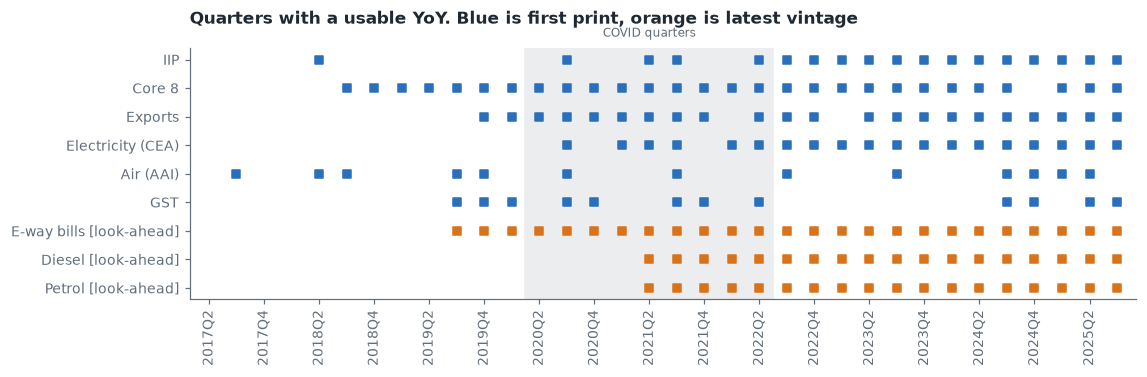

In [2]:
usable = pd.DataFrame([{
    "series": label, "tier": SERIES[label][2], "vintage": SERIES[label][1],
    "complete_levels": int(quarterly[(quarterly.indicator == SERIES[label][0]) & (quarterly.vintage == SERIES[label][1]) & quarterly.complete & quarterly.quarter.isin(WINDOW)].shape[0]),
    "yoy_quarters_all": len(keep(YOY[3][label].index.intersection(WINDOW), "all")),
    "yoy_quarters_ex_covid": len(keep(YOY[3][label].index.intersection(WINDOW), "ex")),
    "first_yoy_quarter": YOY[3][label].index.intersection(WINDOW).min(),
} for label in SERIES]).set_index("series")
display(usable)

fig, ax = plt.subplots(figsize=(10.5, 3.5))
pos = {q: i for i, q in enumerate(WINDOW)}
ax.axvspan(pos["2020Q2"] - .5, pos["2022Q2"] + .5, color=COVID_BAND, zorder=0)
labels = list(SERIES)
for row, label in enumerate(labels):
    xs = [pos[q] for q in YOY[3][label].index if q in pos]
    ax.scatter(xs, [row] * len(xs), s=26, color=ORANGE if SERIES[label][2] == "look-ahead-risk" else BLUE, marker="s", zorder=2)
ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis()
ax.set_xticks(range(0, len(WINDOW), 2), WINDOW[::2], rotation=90); ax.set_xlim(-.7, len(WINDOW) - .3)
ax.text(pos["2021Q2"], -.8, "COVID quarters", ha="center", color=MUTED, fontsize=8)
ax.set_title("Quarters with a usable YoY. Blue is first print, orange is latest vintage", loc="left", color=INK, fontweight="bold", pad=16)
fig.tight_layout(); fig.savefig(REPORTS / "eda_yoy_coverage.png", bbox_inches="tight", facecolor="white"); plt.show()

## 1. Information calendar

For each series and month position in the quarter, the day is the median of `release_date` minus the quarter-end date. Negative days fall before quarter-end. A value counts as first available on that median day.

In [3]:
rows = []
for label, (name, vintage, tier) in SERIES.items():
    x = monthly[(monthly.indicator == name) & (monthly.vintage == vintage) & monthly.value.notna()].copy()
    per = pd.PeriodIndex(x.ref_month, freq="M")
    x["quarter"] = per.asfreq("Q").astype(str); x["pos"] = (per.month - 1) % 3 + 1
    x = x[x.quarter.isin(WINDOW)]
    x["day"] = (x.release_date - pd.PeriodIndex(x.quarter, freq="Q").end_time.normalize()).dt.days
    for m in (1, 2, 3):
        p = x[x.pos == m]
        for sample in SAMPLES:
            d = p[p.quarter.isin(keep(p.quarter.unique(), sample))]
            rows.append({"series": label, "month": m, "sample": sample, "values": len(d), "dated": int(d.day.notna().sum()),
                         "median_day": d.day.median(), "p10": d.day.quantile(.1), "p90": d.day.quantile(.9)})
calendar = pd.DataFrame(rows)
day = calendar.set_index(["series", "sample", "month"])["median_day"]
release_days = {}
for label, (name, vintage, _) in SERIES.items():
    x = monthly[(monthly.indicator == name) & (monthly.vintage == vintage) & monthly.value.notna()].copy()
    per = pd.PeriodIndex(x.ref_month, freq="M")
    x["quarter"] = per.asfreq("Q").astype(str); x["pos"] = (per.month - 1) % 3 + 1
    x["day"] = (x.release_date - pd.PeriodIndex(x.quarter, freq="Q").end_time.normalize()).dt.days
    release_days[label] = x[x.quarter.isin(WINDOW)].pivot(index="quarter", columns="pos", values="day")

gdp_days = (gdp_all.loc[WINDOW, "release_date"] - pd.PeriodIndex(WINDOW, freq="Q").end_time.normalize()).dt.days
GDP_DAY = {s: gdp_days.loc[keep(gdp_days.index, s)].median() for s in SAMPLES}
print("GDP first print, median day after quarter-end:", GDP_DAY, "| range", gdp_days.min(), "to", gdp_days.max())
print("Without the unverified release days:", gdp_days.drop(UNVERIFIED).median())
display(calendar.pivot_table(index=["series", "month"], columns="sample", values=["median_day", "p10", "p90", "dated"], sort=False).dropna(how="all").round(0))
print("No release date at all, so no calendar position:", [k for k in SERIES if calendar[calendar.series == k].dated.sum() == 0])

GDP first print, median day after quarter-end: {'all': np.float64(61.0), 'ex': np.float64(61.0)} | range 57 to 62
Without the unverified release days: 61.0


median_day         p10         p90       dated      
sample                                all    ex   all    ex   all    ex   all    ex
series                   month                                                     
IIP                      1          -19.0 -19.0 -21.0 -20.0 -18.0 -18.0  33.0  24.0
                         2           12.0  12.0  10.0   9.0  12.0  12.0  31.0  23.0
                         3           42.0  42.0  39.0  29.0  43.0  43.0  30.0  22.0
Core 8                   1          -32.0 -31.0 -35.0 -34.0 -30.0 -30.0  33.0  24.0
                         2           -1.0  -1.0  -3.0  -4.0   0.0   0.0  34.0  25.0
                         3           30.0  31.0  26.0  22.0  31.0  31.0  33.0  24.0
Exports                  1          -46.0 -46.0 -58.0 -47.0 -45.0 -44.0  27.0  19.0
                         2          -16.0 -16.0 -28.0 -17.0 -15.0 -14.0  28.0  20.0
                         3           15.0  15.0   2.0  14.0  15.0  16.0  28.0  20.0
Electricity (CEA)        1            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         2            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         3            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
Air (AAI)                1          -36.0 -35.0 -40.0 -40.0 -31.0 -31.0  32.0  23.0
                         2           -7.0  -7.0 -11.0 -10.0  -1.0  -1.0  33.0  24.0
                         3           23.0  24.0  21.0  21.0  32.0  33.0  25.0  20.0
GST                      1          -60.0 -60.0 -60.0 -60.0 -60.0 -59.0  19.0  13.0
                         2          -30.0 -30.0 -30.0 -30.0 -29.0 -29.0  20.0  13.0
                         3            1.0   1.0   1.0   1.0   1.0   1.0  20.0  11.0
E-way bills [look-ahead] 1            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         2            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         3            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
Diesel [look-ahead]      1            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         2            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         3            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
Petrol [look-ahead]      1            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         2            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0
                         3            NaN   NaN   NaN   NaN   NaN   NaN   0.0   0.0

No release date at all, so no calendar position: ['Electricity (CEA)', 'E-way bills [look-ahead]', 'Diesel [look-ahead]', 'Petrol [look-ahead]']


Core 8 months 1-3 out by day 30 vs day 32, share of quarters: 0.59 1.0


months_available                   months_available_ex_covid                   on_time_share                    
date                                  D+0     D+32     D+45                       D+0     D+32     D+45           D+0      D+32      D+45
series                                                                                                                                   
IIP                                     1        2        3                         1        2        3           1.0       1.0       1.0
Core 8                                  2        3        3                         2        3        3      0.939394       1.0       1.0
Exports                                 2        3        3                         2        3        3           1.0       1.0       1.0
Electricity (CEA)                 undated  undated  undated                   undated  undated  undated           NaN       NaN       NaN
Air (AAI)                               2        3        3                         2        3        3      0.967742  0.913043  0.956522
GST                                     2        3        3                         2        3        3           1.0       1.0       1.0
E-way bills [look-ahead]          undated  undated  undated                   undated  undated  undated           NaN       NaN       NaN
Diesel [look-ahead]               undated  undated  undated                   undated  undated  undated           NaN       NaN       NaN
Petrol [look-ahead]               undated  undated  undated                   undated  undated  undated           NaN       NaN       NaN

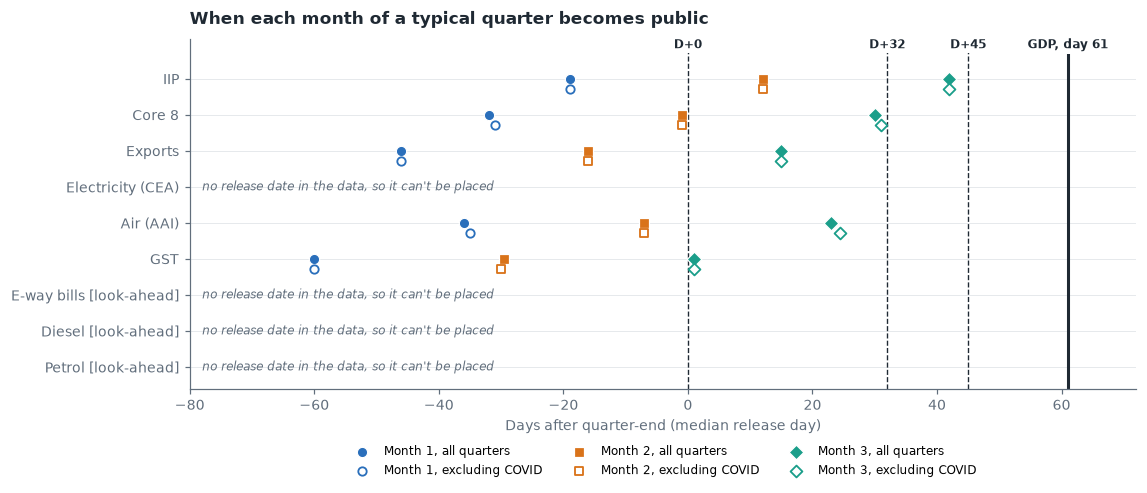

In [4]:
NOWCAST_DATES = {"D+0": 0, "D+32": 32, "D+45": 45}
DATED = [k for k in SERIES if calendar[calendar.series == k].dated.sum() > 0]
UNDATED = [k for k in SERIES if k not in DATED]

def months_by(label, d, sample="all"):
    k = 0
    for m in (1, 2, 3):
        if day[(label, sample, m)] <= d:
            k = m
        else:
            break
    return k

def on_time(label, d, k, sample="all"):
    """Share of quarters whose first k months had all really been released by day d."""
    if k == 0:
        return np.nan, 0
    t = release_days[label].reindex(columns=range(1, k + 1)).dropna()
    t = t.loc[keep(t.index, sample)]
    return ((t <= d).all(axis=1)).mean(), len(t)

avail = []
for label in SERIES:
    for name, d in NOWCAST_DATES.items():
        if label in UNDATED:
            avail.append({"series": label, "date": name, "months_available": "undated", "months_available_ex_covid": "undated", "on_time_share": np.nan, "on_time_n": 0})
        else:
            k = months_by(label, d)
            share, n = on_time(label, d, k)
            avail.append({"series": label, "date": name, "months_available": k, "months_available_ex_covid": months_by(label, d, "ex"), "on_time_share": share, "on_time_n": n})
avail = pd.DataFrame(avail)
print("Core 8 months 1-3 out by day 30 vs day 32, share of quarters:", round(on_time("Core 8", 30, 3)[0], 2), round(on_time("Core 8", 32, 3)[0], 2))
display(avail.pivot(index="series", columns="date", values=["months_available", "months_available_ex_covid", "on_time_share"]).loc[list(SERIES)].round(2))
avail.to_csv(PROCESSED / "eda_nowcast_availability.csv", index=False)

fig, ax = plt.subplots(figsize=(10.5, 4.6))
MCOL = {1: BLUE, 2: ORANGE, 3: TEAL}; MARK = {1: "o", 2: "s", 3: "D"}
for row, label in enumerate(SERIES):
    ax.axhline(row, color=GRID, lw=.6, zorder=0)
    if label in UNDATED:
        ax.text(-78, row, "no release date in the data, so it can't be placed", va="center", color=MUTED, fontsize=8, style="italic")
        continue
    for m in (1, 2, 3):
        a, e = day[(label, "all", m)], day[(label, "ex", m)]
        ax.scatter(a, row, s=46, color=MCOL[m], marker=MARK[m], zorder=3, edgecolor="white", linewidth=.8, label=f"Month {m}, all quarters" if row == 0 else None)
        ax.scatter(e, row + .28, s=30, facecolor="white", edgecolor=MCOL[m], marker=MARK[m], zorder=3, linewidth=1.2, label=f"Month {m}, excluding COVID" if row == 0 else None)
for name, d in NOWCAST_DATES.items():
    ax.axvline(d, color=INK, lw=.9, ls="--", zorder=1)
    ax.text(d, -.85, name, ha="center", color=INK, fontsize=8, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
ax.axvline(GDP_DAY["all"], color=INK, lw=2, zorder=1)
ax.text(GDP_DAY["all"], -.85, f"GDP, day {GDP_DAY['all']:.0f}", ha="center", color=INK, fontsize=8, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
ax.set_yticks(range(len(SERIES)), list(SERIES)); ax.set_ylim(len(SERIES) - .4, -1.1)
ax.set_xlim(-80, 72); ax.set_xlabel("Days after quarter-end (median release day)")
ax.set_title("When each month of a typical quarter becomes public", loc="left", color=INK, fontweight="bold", pad=10)
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.13), fontsize=8)
fig.tight_layout(); fig.savefig(REPORTS / "eda_information_calendar.png", bbox_inches="tight", facecolor="white"); plt.show()

**Reading the calendar**

- **D+0, D+32 and D+45** are the three nowcast dates, leaving about 61, 29 and 16 days before the GDP first print.
- **Why D+32 and not D+30:** core 8's month 3 arrives on day 30 or 31, so D+30 would catch it in only about 6 quarters out of 10. D+32 is the day after the 90th percentile. D+45 follows IIP's month 3 (day 42, 90th percentile day 43). D+0 misses GST's month 3 by one day.
- **Availability** comes from the table above. `months_available` is how many months of the quarter are out by median day, and `on_time_share` is how often they were really out by that day.
- **Undated series:** CEA, e-way bills, diesel and petrol have no release dates, so no availability is claimed for them. The months they have are still correlated in section 2.
- **Date quality:** core 8 and AAI dates are PDF creation dates, a proxy for release. GST dates stop at Mar 2024, because later values come from an undated file.
- **Exports:** from Sep 2020 to Nov 2021 the first print came within 1 to 3 days of month-end, against about 15 days otherwise. Those releases may be early estimates, which isn't verified here, so first-print timing isn't uniform.

## 2. Partial-quarter signal

For each series, quarterly YoY is computed from (a) month 1, (b) months 1 and 2, (c) all three, then correlated with GDP first-print growth.

The fairest comparison uses the **common sample**: quarters where all three versions exist. The own-sample columns use every quarter available for that version, so they can differ partly because the quarters differ.

all quarters


,r_common a: month 1,r_common b: months 1-2,r_common c: all 3,r_own a: month 1,r_own b: months 1-2,r_own c: all 3,n_own a: month 1,n_own b: months 1-2,n_own c: all 3,n_common,ci_common
series,,,,,,,,,,,
IIP,0.72,0.80,0.83,0.71,0.80,0.83,28.0,24.0,18.0,18,0.60 to 0.94
Core 8,0.87,0.93,0.94,0.87,0.93,0.94,29.0,29.0,28.0,28,0.87 to 0.97
Exports,0.68,0.73,0.69,0.68,0.73,0.69,22.0,22.0,22.0,22,0.37 to 0.86
Electricity (CEA),0.64,0.65,0.53,0.64,0.65,0.53,19.0,19.0,19.0,19,0.10 to 0.79
Air (AAI),0.69,0.70,0.75,0.40,0.67,0.75,29.0,27.0,13.0,13,0.33 to 0.92
GST,0.68,0.79,0.79,0.62,0.73,0.79,19.0,17.0,12.0,12,0.40 to 0.94
E-way bills [look-ahead],0.55,0.75,0.83,0.55,0.75,0.83,25.0,25.0,25.0,25,0.65 to 0.92
Diesel [look-ahead],0.86,0.84,0.76,0.86,0.84,0.76,18.0,18.0,18.0,18,0.45 to 0.91
Petrol [look-ahead],0.86,0.94,0.91,0.86,0.94,0.91,18.0,18.0,18.0,18,0.76 to 0.96


excluding COVID


,r_common a: month 1,r_common b: months 1-2,r_common c: all 3,r_own a: month 1,r_own b: months 1-2,r_own c: all 3,n_own a: month 1,n_own b: months 1-2,n_own c: all 3,n_common,ci_common
series,,,,,,,,,,,
IIP,0.56,0.47,0.49,0.57,0.64,0.49,20.0,18.0,14.0,14,-0.05 to 0.81
Core 8,0.51,0.53,0.65,0.51,0.53,0.65,20.0,20.0,19.0,19,0.28 to 0.85
Exports,0.32,0.22,0.48,0.32,0.22,0.48,14.0,14.0,14.0,14,-0.06 to 0.81
Electricity (CEA),0.18,0.03,-0.06,0.18,0.03,-0.06,13.0,13.0,13.0,13,-0.59 to 0.51
Air (AAI),0.21,0.20,0.23,0.12,0.05,0.23,20.0,19.0,11.0,11,-0.43 to 0.73
GST,0.37,0.44,0.81,0.25,0.30,0.81,14.0,12.0,7.0,7,0.15 to 0.97
E-way bills [look-ahead],-0.10,-0.03,0.29,-0.10,-0.03,0.29,16.0,16.0,16.0,16,-0.24 to 0.69
Diesel [look-ahead],-0.04,-0.43,-0.41,-0.04,-0.43,-0.41,13.0,13.0,13.0,13,-0.78 to 0.18
Petrol [look-ahead],-0.55,-0.60,-0.55,-0.55,-0.60,-0.55,13.0,13.0,13.0,13,-0.84 to 0.01


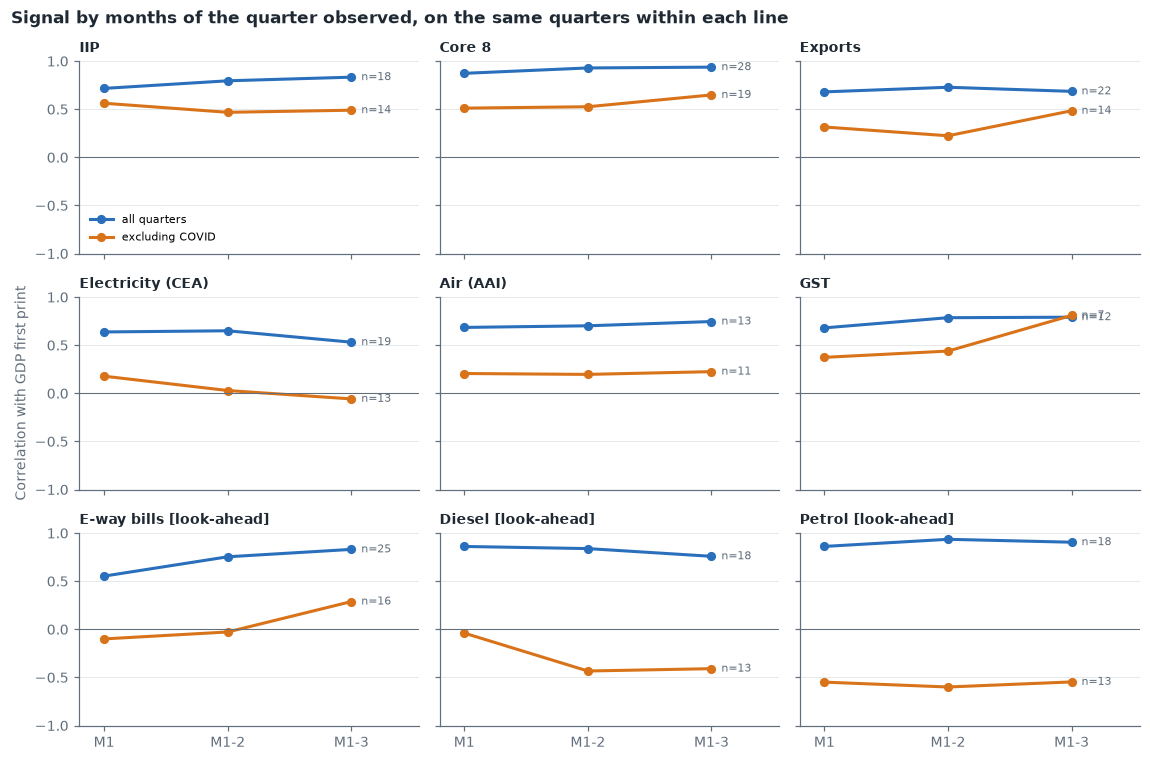

In [5]:
VERSIONS = {1: "a: month 1", 2: "b: months 1-2", 3: "c: all 3"}
rows = []
for label in SERIES:
    common = YOY[1][label].index.intersection(YOY[2][label].index).intersection(YOY[3][label].index).intersection(gdp.index)
    for sample in SAMPLES:
        cq = keep(common, sample)
        for k, version in VERSIONS.items():
            own = keep(YOY[k][label].index.intersection(gdp.index), sample)
            r_own, n_own = corr(YOY[k][label], gdp, own)
            r_c, n_c = corr(YOY[k][label], gdp, cq)
            rows.append({"series": label, "sample": sample, "k": k, "version": version, "r_common": r_c, "n_common": n_c, "ci_common": ci_text(r_c, n_c),
                         "r_own": r_own, "n_own": n_own, "ci_own": ci_text(r_own, n_own), "thin": n_c < THIN})
partial = pd.DataFrame(rows)
partial.to_csv(PROCESSED / "eda_partial_signal.csv", index=False)
for sample, title in SAMPLES.items():
    print(title)
    wide = partial[partial["sample"] == sample].pivot(index="series", columns="version", values=["r_common", "r_own", "n_own"]).loc[list(SERIES)].round(2)
    wide.columns = [f"{a} {b}" for a, b in wide.columns]
    display(wide.join(partial[(partial["sample"] == sample) & (partial.k == 3)].set_index("series")[["n_common", "ci_common"]]))

fig, axes = plt.subplots(3, 3, figsize=(10.5, 7), sharex=True, sharey=True)
for ax, label in zip(axes.flat, SERIES):
    for sample, color, text in (("all", BLUE, "all quarters"), ("ex", ORANGE, "excluding COVID")):
        d = partial[(partial.series == label) & (partial["sample"] == sample)]
        ax.plot(d.k, d.r_common, color=color, marker="o", ms=5, lw=2, label=text)
        ax.text(3.08, d.r_common.iloc[-1], f"n={d.n_common.iloc[-1]}", color=MUTED, fontsize=7.5, va="center")
    ax.axhline(0, color=MUTED, lw=.7); ax.grid(axis="y", color=GRID, lw=.6)
    ax.set_title(label, loc="left", fontsize=9, color=INK, fontweight="bold")
    ax.set_xticks([1, 2, 3], ["M1", "M1-2", "M1-3"]); ax.set_xlim(.8, 3.55); ax.set_ylim(-1, 1)
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="lower left"); axes[1, 0].set_ylabel("Correlation with GDP first print")
fig.suptitle("Signal by months of the quarter observed, on the same quarters within each line", x=.01, ha="left", color=INK, fontweight="bold")
fig.tight_layout(); fig.savefig(REPORTS / "eda_partial_signal.png", bbox_inches="tight", facecolor="white"); plt.show()

### Signal arriving by nowcast date

This maps each dated series to the months available on each date. A series with no month out yet has no signal on that date. Undated series are left out, because their availability is unknown.

all quarters


months           r_common             on_time            
date         D+0 D+32 D+45      D+0  D+32  D+45     D+0  D+32  D+45
series                                                             
IIP          1.0  2.0  3.0     0.72  0.80  0.83    1.00  1.00  1.00
Core 8       2.0  3.0  3.0     0.93  0.94  0.94    0.94  1.00  1.00
Exports      2.0  3.0  3.0     0.73  0.69  0.69    1.00  1.00  1.00
Air (AAI)    2.0  3.0  3.0     0.70  0.75  0.75    0.97  0.91  0.96
GST          2.0  3.0  3.0     0.79  0.79  0.79    1.00  1.00  1.00

excluding COVID


months           r_common             on_time            
date         D+0 D+32 D+45      D+0  D+32  D+45     D+0  D+32  D+45
series                                                             
IIP          1.0  2.0  3.0     0.56  0.47  0.49    1.00  1.00  1.00
Core 8       2.0  3.0  3.0     0.53  0.65  0.65    0.92  1.00  1.00
Exports      2.0  3.0  3.0     0.22  0.48  0.48    1.00  1.00  1.00
Air (AAI)    2.0  3.0  3.0     0.20  0.23  0.23    0.95  0.89  0.94
GST          2.0  3.0  3.0     0.44  0.81  0.81    1.00  1.00  1.00

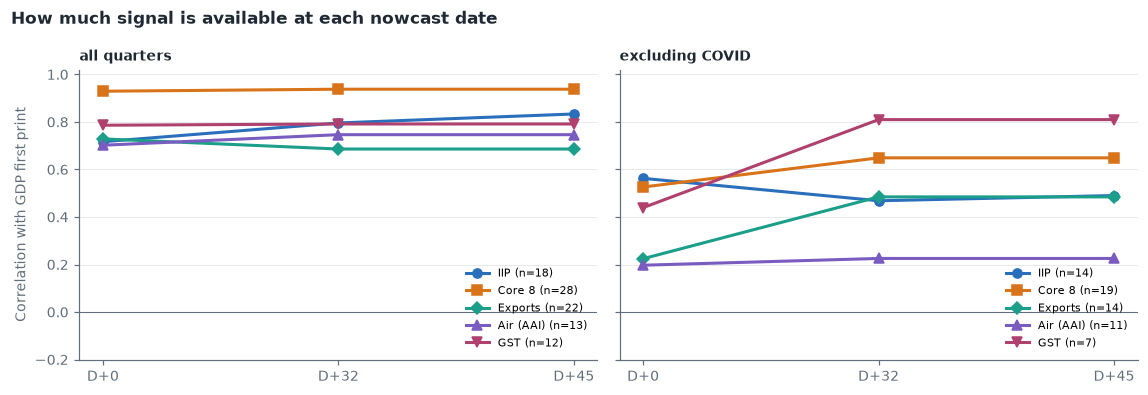

In [6]:
rows = []
for label in DATED:
    common = YOY[1][label].index.intersection(YOY[2][label].index).intersection(YOY[3][label].index).intersection(gdp.index)
    for name, d in NOWCAST_DATES.items():
        for sample in SAMPLES:
            k = months_by(label, d, sample)
            if k == 0:
                rows.append({"series": label, "date": name, "sample": sample, "months": 0, "r_common": np.nan, "n_common": 0, "ci": "", "on_time": np.nan})
                continue
            r, n = corr(YOY[k][label], gdp, keep(common, sample))
            rows.append({"series": label, "date": name, "sample": sample, "months": k, "r_common": r, "n_common": n, "ci": ci_text(r, n), "on_time": on_time(label, d, k, sample)[0]})
by_date = pd.DataFrame(rows)
by_date.to_csv(PROCESSED / "eda_signal_by_date.csv", index=False)
for sample, title in SAMPLES.items():
    print(title); display(by_date[by_date["sample"] == sample].pivot(index="series", columns="date", values=["months", "r_common", "on_time"]).loc[DATED].round(2))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
SER_COL = dict(zip(DATED, [BLUE, ORANGE, TEAL, "#7a5cc0", "#b0416e"]))
SER_MARK = dict(zip(DATED, ["o", "s", "D", "^", "v"]))
for ax, (sample, title) in zip(axes, SAMPLES.items()):
    for label in DATED:
        d = by_date[(by_date.series == label) & (by_date["sample"] == sample)]
        x = [list(NOWCAST_DATES).index(v) for v in d.date]
        ax.plot(x, d.r_common, color=SER_COL[label], marker=SER_MARK[label], ms=6, lw=2, label=f"{label} (n={d.n_common.max()})")
    ax.set_xticks(range(3), list(NOWCAST_DATES)); ax.axhline(0, color=MUTED, lw=.7); ax.grid(axis="y", color=GRID, lw=.6); ax.set_ylim(-.2, 1.02)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=9); ax.legend(frameon=False, fontsize=7.5, loc="lower right")
axes[0].set_ylabel("Correlation with GDP first print")
fig.suptitle("How much signal is available at each nowcast date", x=.01, ha="left", color=INK, fontweight="bold")
fig.tight_layout(); fig.savefig(REPORTS / "eda_signal_by_date.png", bbox_inches="tight", facecolor="white"); plt.show()

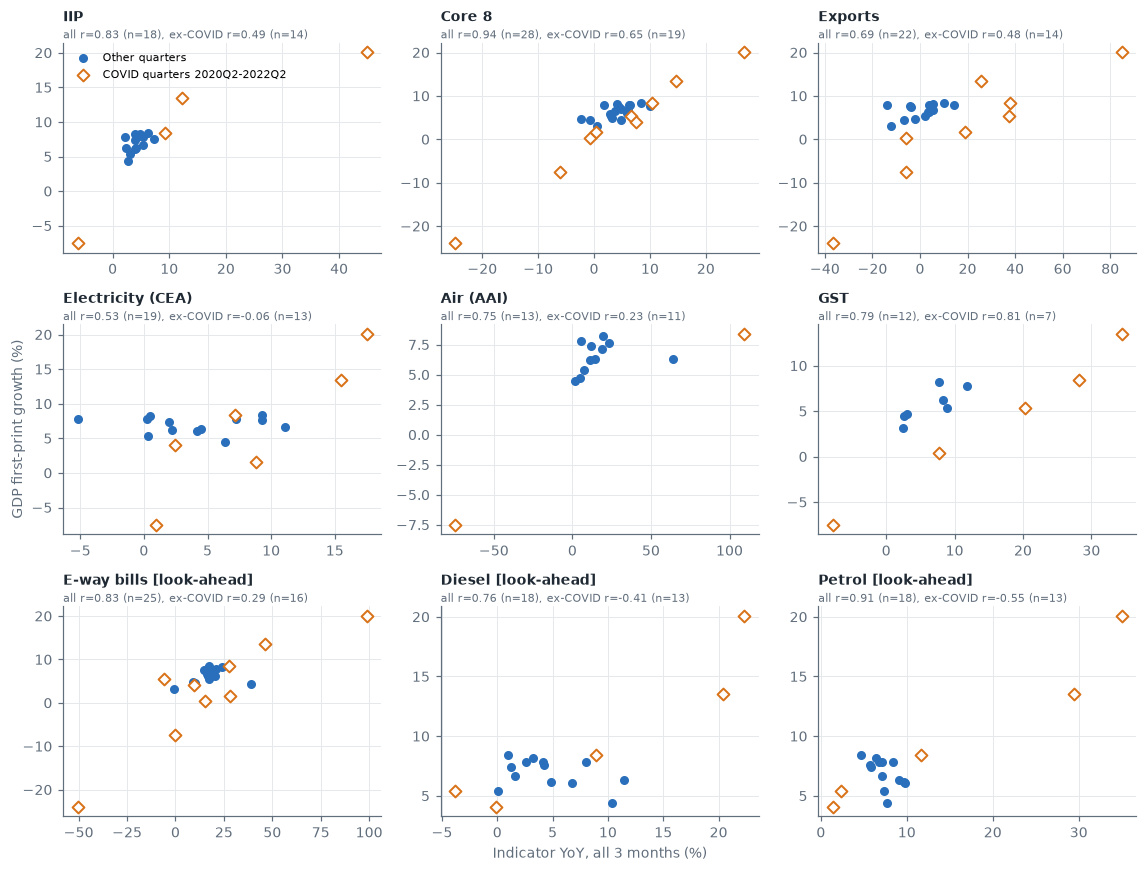

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(10.5, 8))
for ax, label in zip(axes.flat, SERIES):
    x = YOY[3][label]; idx = x.index.intersection(gdp.index)
    calm, covid = [q for q in idx if q not in COVID], [q for q in idx if q in COVID]
    ax.scatter(x[calm], gdp[calm], s=24, color=BLUE, label="Other quarters", zorder=3)
    ax.scatter(x[covid], gdp[covid], s=30, facecolor="white", edgecolor=ORANGE, marker="D", linewidth=1.3, label="COVID quarters 2020Q2-2022Q2", zorder=3)
    ra, na = corr(x, gdp, keep(idx, "all")); re, ne = corr(x, gdp, keep(idx, "ex"))
    ax.set_title(label, loc="left", fontsize=9, color=INK, fontweight="bold", pad=14)
    ax.text(0, 1.02, f"all r={ra:.2f} (n={na}), ex-COVID r={re:.2f} (n={ne})", transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.grid(color=GRID, lw=.6); ax.set_axisbelow(True)
axes[0, 0].legend(frameon=False, fontsize=7, loc="upper left")
axes[2, 1].set_xlabel("Indicator YoY, all 3 months (%)"); axes[1, 0].set_ylabel("GDP first-print growth (%)")
fig.tight_layout(); fig.savefig(REPORTS / "eda_scatter_gdp.png", bbox_inches="tight", facecolor="white"); plt.show()

## 3. Lead/lag

The table shows the correlation of indicator YoY at quarter `t + lag` with GDP at quarter `t`. **A negative lag means the indicator comes first.** Lag -1 pairs last quarter's indicator with this quarter's GDP.

GDP stays inside the window, while the indicator may come from just outside it. Excluding COVID drops a pair if either of its two quarters is a COVID quarter.

YoY growth overlaps across quarters and persists, so neighbouring lags are not independent evidence.

all quarters


,-2,-1,0,1,2,n_-2,n_-1,n_0,n_1,n_2,strongest_lag,strongest_r
series,,,,,,,,,,,,
IIP,-0.05,0.42,0.83,0.13,-0.46,16,17,18,18,18,0,0.83
Core 8,0.24,0.40,0.94,0.31,0.10,26,27,28,28,29,0,0.94
Exports,0.16,0.39,0.69,0.18,0.02,20,21,22,23,24,0,0.69
Electricity (CEA),-0.21,0.10,0.53,0.04,-0.28,17,18,19,20,21,0,0.53
Air (AAI),0.15,0.36,0.75,0.92,-0.28,12,13,13,13,13,1,0.92
GST,0.29,0.35,0.79,0.56,0.11,10,11,12,13,14,0,0.79
E-way bills [look-ahead],0.16,0.43,0.83,0.10,-0.13,23,24,25,26,27,0,0.83
Diesel [look-ahead],-0.57,-0.09,0.76,-0.16,-0.56,16,17,18,19,20,0,0.76
Petrol [look-ahead],-0.50,-0.07,0.91,-0.31,-0.51,16,17,18,19,20,0,0.91


excluding COVID


,-2,-1,0,1,2,n_-2,n_-1,n_0,n_1,n_2,strongest_lag,strongest_r
series,,,,,,,,,,,,
IIP,-0.14,0.38,0.49,0.42,0.19,12,13,14,13,12,0.0,0.49
Core 8,0.62,0.63,0.65,0.60,0.32,15,17,19,18,18,0.0,0.65
Exports,-0.85,-0.07,0.48,0.63,0.75,10,12,14,14,14,-2.0,-0.85
Electricity (CEA),-0.54,-0.26,-0.06,0.10,0.21,11,12,13,13,13,-2.0,-0.54
Air (AAI),0.04,-0.16,0.23,0.68,0.07,9,11,11,10,10,1.0,0.68
GST,0.99,0.91,0.81,0.32,0.30,3,5,7,8,9,NaN,NaN
E-way bills [look-ahead],0.39,0.21,0.29,0.38,0.54,12,14,16,16,16,2.0,0.54
Diesel [look-ahead],0.06,-0.37,-0.41,-0.44,-0.48,11,12,13,13,13,2.0,-0.48
Petrol [look-ahead],-0.18,-0.37,-0.55,-0.61,-0.07,11,12,13,13,13,1.0,-0.61


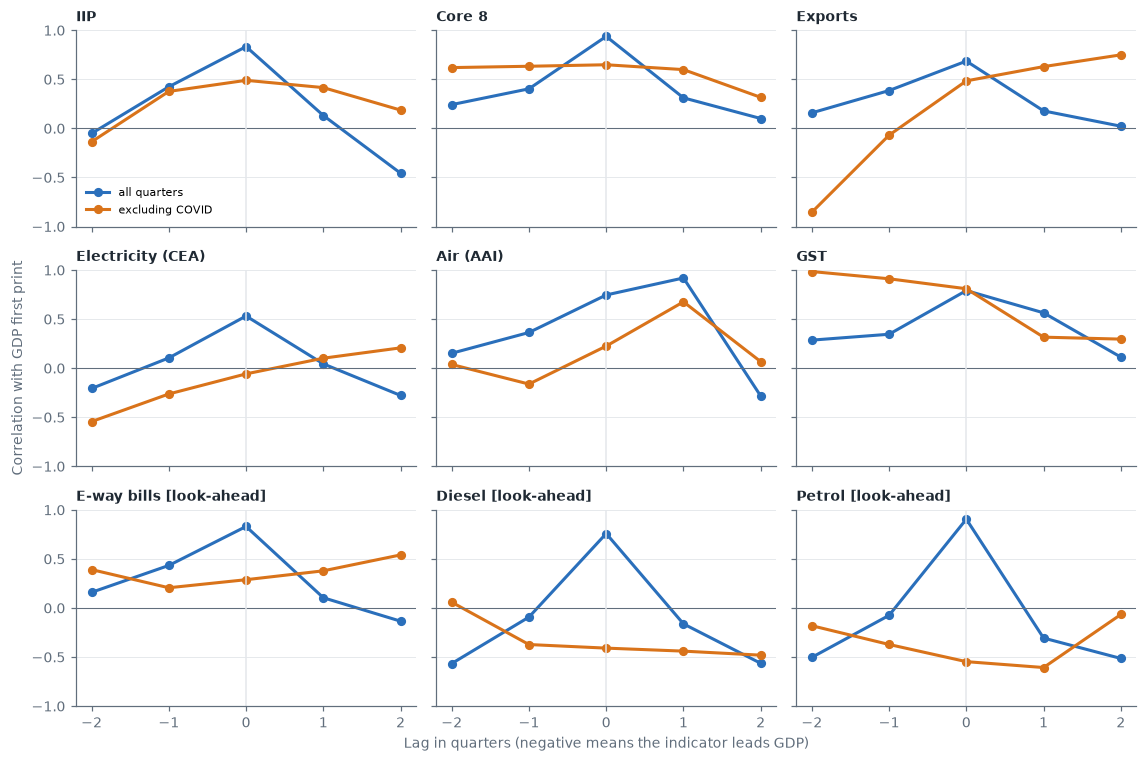

In [8]:
LAGS = [-2, -1, 0, 1, 2]

def lagged(label, lag, sample):
    x = YOY[3][label]
    pairs = [(q, str(pd.Period(q, freq="Q") + lag)) for q in gdp.index]
    pairs = [(q, s) for q, s in pairs if s in x.index and (sample == "all" or (q not in COVID and s not in COVID))]
    if len(pairs) < 3:
        return np.nan, len(pairs)
    return np.corrcoef(gdp.loc[[q for q, _ in pairs]], x.loc[[s for _, s in pairs]])[0, 1], len(pairs)

rows = [{"series": label, "sample": s, "lag": lag, "r": lagged(label, lag, s)[0], "n": lagged(label, lag, s)[1]} for label in SERIES for s in SAMPLES for lag in LAGS]
leadlag = pd.DataFrame(rows)
leadlag["ci"] = [ci_text(r, n) for r, n in zip(leadlag.r, leadlag.n)]
leadlag.to_csv(PROCESSED / "eda_lead_lag.csv", index=False)
for sample, title in SAMPLES.items():
    d = leadlag[leadlag["sample"] == sample]
    best = d[d.n >= THIN]; best = best.loc[best.groupby("series").r.apply(lambda s: s.abs().idxmax())].set_index("series")
    print(title)
    display(d.pivot(index="series", columns="lag", values="r").loc[list(SERIES)].round(2)
            .join(d.pivot(index="series", columns="lag", values="n").add_prefix("n_")).join(best[["lag", "r"]].rename(columns={"lag": "strongest_lag", "r": "strongest_r"}).round(2)))

fig, axes = plt.subplots(3, 3, figsize=(10.5, 7), sharex=True, sharey=True)
for ax, label in zip(axes.flat, SERIES):
    for sample, color, text in (("all", BLUE, "all quarters"), ("ex", ORANGE, "excluding COVID")):
        d = leadlag[(leadlag.series == label) & (leadlag["sample"] == sample)]
        ax.plot(d.lag, d.r, color=color, marker="o", ms=5, lw=2, label=text)
    ax.axhline(0, color=MUTED, lw=.7); ax.axvline(0, color=GRID, lw=1); ax.grid(axis="y", color=GRID, lw=.6)
    ax.set_title(label, loc="left", fontsize=9, color=INK, fontweight="bold"); ax.set_ylim(-1, 1); ax.set_xticks(LAGS)
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="lower left")
axes[2, 1].set_xlabel("Lag in quarters (negative means the indicator leads GDP)"); axes[1, 0].set_ylabel("Correlation with GDP first print")
fig.tight_layout(); fig.savefig(REPORTS / "eda_lead_lag.png", bbox_inches="tight", facecolor="white"); plt.show()

**The AAI peak at lag +1 is an artefact, not a timing effect.** The months are aligned correctly (Apr 2020 shows 10,874 passengers during the flight ban). But AAI has no usable YoY for 2020Q2 or 2021Q2, so its extreme 2020Q3 (-75%) and 2021Q3 (+109%) values line up with GDP's extreme quarter just before them.

**Strongest lag** only considers lags with at least 10 quarters. Even so, with 9 series and 5 lags twice over, a few large values are expected by chance, such as exports at lag -2 excluding COVID (r = -0.85, n = 10), which has the wrong sign for a leading activity series.

## 4. Redundancy

Pairwise correlations between 3-month YoY series, each on the quarters both series share inside the window. Pairs with absolute correlation above 0.85 are flagged. Pairs on fewer than 10 quarters can't be trusted either way, including those with large values.

r             n     above_0.85       
sample                                                  all        ex all  ex        all     ex
a                        b                                                                     
Air (AAI)                Diesel [look-ahead]       0.809591  0.925835   7   6      False   True
                         E-way bills [look-ahead]  0.874502  0.459326  10   8       True  False
                         GST                       0.961528   0.51795   7   5       True  False
Core 8                   E-way bills [look-ahead]   0.86408  0.378906  24  15       True  False
                         GST                       0.969552  0.705857  11   6       True  False
Diesel [look-ahead]      Petrol [look-ahead]       0.902522  0.518691  18  13       True  False
E-way bills [look-ahead] Diesel [look-ahead]       0.851682  0.468895  18  13       True  False
                         Petrol [look-ahead]       0.892891  0.061182  18  13       True  False
Electricity (CEA)        GST                       0.739582 -0.935083   7   4      False   True
Exports                  GST                          0.853  0.799517  11   6       True  False
IIP                      Core 8                    0.938422  0.844353  16  12       True  False
                         E-way bills [look-ahead]  0.935544 -0.493124  17  13       True  False
                         Exports                   0.908434   0.15375  16  12       True  False
                         GST                       0.961883 -0.931094   7   4       True   True

IIP vs core 8:


,a,b,sample,r,n,ci,above_0.85,thin
0,IIP,Core 8,all,0.94,16,0.83 to 0.98,True,False
36,IIP,Core 8,ex,0.84,12,0.52 to 0.96,False,False


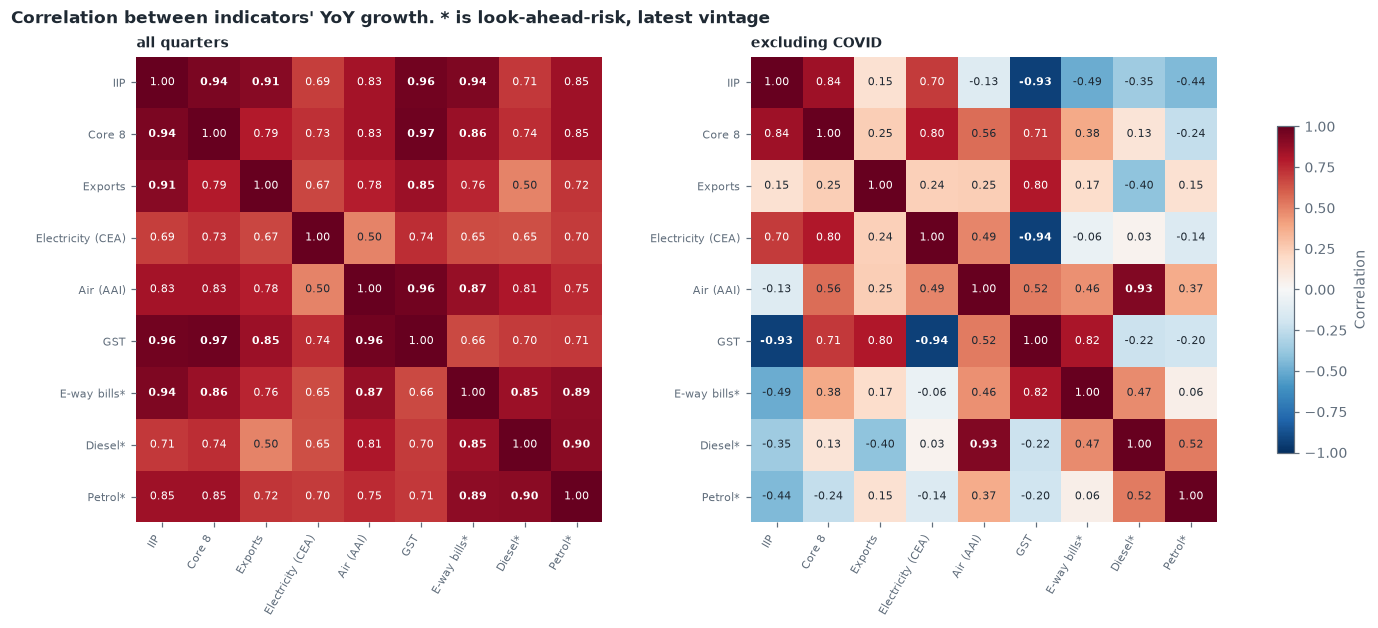

In [9]:
frame = pd.DataFrame({k: YOY[3][k] for k in SERIES}).reindex(WINDOW)
MATS, NS = {}, {}
for sample in SAMPLES:
    f = frame.loc[keep(frame.index, sample)]
    MATS[sample], NS[sample] = f.corr(min_periods=3), f.notna().astype(int).T @ f.notna().astype(int)
pairs = []
labels = list(SERIES)
for sample in SAMPLES:
    for i, a in enumerate(labels):
        for b in labels[i + 1:]:
            r, n = MATS[sample].loc[a, b], NS[sample].loc[a, b]
            pairs.append({"a": a, "b": b, "sample": sample, "r": r, "n": n, "ci": ci_text(r, n), "above_0.85": abs(r) > .85, "thin": n < THIN})
pairs = pd.DataFrame(pairs)
pairs.to_csv(PROCESSED / "eda_redundancy_pairs.csv", index=False)
wide = pairs.pivot(index=["a", "b"], columns="sample", values=["r", "n", "above_0.85"])
display(wide[wide["above_0.85"].any(axis=1)].round(2))
print("IIP vs core 8:"); display(pairs[(pairs.a == "IIP") & (pairs.b == "Core 8")].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6), layout="constrained")
for ax, (sample, title) in zip(axes, SAMPLES.items()):
    im = ax.imshow(MATS[sample].values, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = MATS[sample].values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > .6 else INK, fontweight="bold" if abs(v) > .85 and i != j else None)
    ax.set_xticks(range(len(labels)), [k.replace(" [look-ahead]", "*") for k in labels], rotation=60, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(labels)), [k.replace(" [look-ahead]", "*") for k in labels], fontsize=7.5)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=9); ax.spines[:].set_visible(False)
fig.suptitle("Correlation between indicators' YoY growth. * is look-ahead-risk, latest vintage", x=.01, ha="left", color=INK, fontweight="bold")
fig.colorbar(im, ax=axes, shrink=.7, label="Correlation")
fig.savefig(REPORTS / "eda_redundancy.png", bbox_inches="tight", facecolor="white"); plt.show()

## 5. Like-for-like add-on check

Each add-on and look-ahead series is compared with IIP and with core 8 on exactly the quarters both have with GDP. These comparisons use a different sample for each row, so rows can't be ranked against each other.

The interval on `diff` is a percentile bootstrap of quarters (2,000 draws, fixed seed). It ignores autocorrelation, so it is if anything too narrow. If it spans 0, the data can't separate the series from the benchmark.

all quarters


n  r_series  r_benchmark  diff  diff_lo  diff_hi   thin
series                   benchmark                                                          
Exports                  IIP        16      0.72         0.84 -0.12    -0.58     0.01  False
                         Core 8     21      0.69         0.95 -0.26    -0.60    -0.10  False
Electricity (CEA)        IIP        17      0.58         0.84 -0.25    -0.76    -0.06  False
                         Core 8     18      0.53         0.91 -0.37    -0.82    -0.12  False
Air (AAI)                IIP         9      0.75         0.89 -0.14    -0.75     0.16   True
                         Core 8     10      0.76         0.77 -0.01    -0.54     0.20  False
GST                      IIP         7      0.85         0.92 -0.08    -0.16     0.21   True
                         Core 8     11      0.80         0.84 -0.04    -0.22     0.04  False
E-way bills [look-ahead] IIP        17      0.79         0.84 -0.04    -0.75     0.04  False
                         Core 8     24      0.83         0.94 -0.11    -0.40    -0.01  False
Diesel [look-ahead]      IIP        16      0.74         0.93 -0.19    -1.03    -0.01  False
                         Core 8     17      0.76         0.89 -0.13    -0.46     0.30  False
Petrol [look-ahead]      IIP        16      0.90         0.93 -0.03    -1.02     0.04  False
                         Core 8     17      0.91         0.89  0.02    -0.23     0.49  False

excluding COVID


n  r_series  r_benchmark  diff  diff_lo  diff_hi   thin
series                   benchmark                                                          
Exports                  IIP        12      0.26         0.48 -0.22    -0.83     0.34  False
                         Core 8     13      0.49         0.61 -0.12    -0.70     0.41  False
Electricity (CEA)        IIP        13     -0.06         0.48 -0.54    -0.92    -0.15  False
                         Core 8     12     -0.08         0.25 -0.33    -0.64    -0.03  False
Air (AAI)                IIP         7     -0.14         0.38 -0.52    -1.50     0.35   True
                         Core 8      8      0.22         0.70 -0.48    -0.79     0.06   True
GST                      IIP         4      0.20        -0.11  0.31      NaN      NaN   True
                         Core 8      6      0.81         0.65  0.16    -0.25     0.68   True
E-way bills [look-ahead] IIP        13     -0.53         0.48 -1.01    -1.55     0.30  False
                         Core 8     15      0.29         0.65 -0.36    -1.02     0.27  False
Diesel [look-ahead]      IIP        13     -0.41         0.48 -0.89    -1.51     0.05  False
                         Core 8     12     -0.41         0.25 -0.66    -1.26     0.14  False
Petrol [look-ahead]      IIP        13     -0.55         0.48 -1.03    -1.48    -0.55  False
                         Core 8     12     -0.53         0.25 -0.78    -1.37    -0.19  False

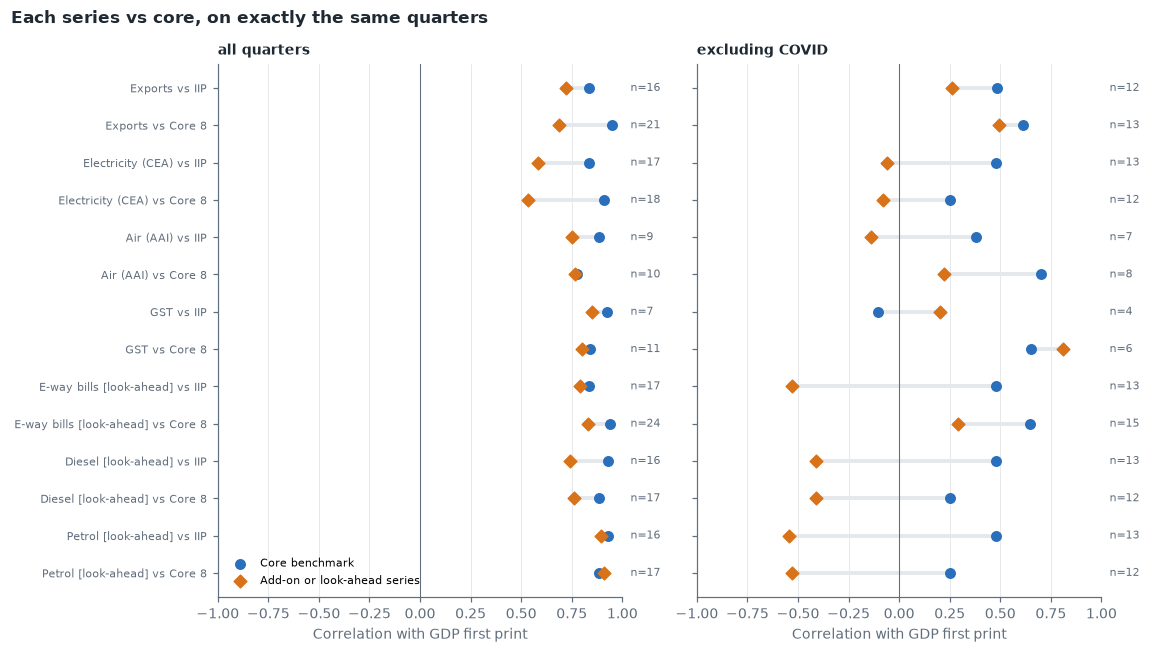

In [10]:
RNG = np.random.default_rng(3)

def boot_diff(x, b, y, draws=2000):
    x, b, y = map(np.asarray, (x, b, y))
    if len(x) < 6:
        return np.nan, np.nan
    d = []
    for _ in range(draws):
        i = RNG.integers(0, len(x), len(x))
        if x[i].std() > 0 and b[i].std() > 0 and y[i].std() > 0:
            d.append(np.corrcoef(x[i], y[i])[0, 1] - np.corrcoef(b[i], y[i])[0, 1])
    return tuple(np.percentile(d, [2.5, 97.5]))

def like_for_like(drop=()):
    rows = []
    for label in OTHERS:
        for bench in CORE:
            shared = YOY[3][label].index.intersection(YOY[3][bench].index).intersection(gdp.index)
            for sample in SAMPLES:
                q = keep(shared, sample, drop)
                r1, n = corr(YOY[3][label], gdp, q); r2, _ = corr(YOY[3][bench], gdp, q)
                lo, hi = boot_diff(YOY[3][label].loc[q], YOY[3][bench].loc[q], gdp.loc[q]) if n else (np.nan, np.nan)
                rows.append({"series": label, "benchmark": bench, "sample": sample, "n": n, "r_series": r1, "r_benchmark": r2, "diff": r1 - r2, "diff_lo": lo, "diff_hi": hi, "thin": n < THIN})
    return pd.DataFrame(rows)

lfl = like_for_like()
lfl.to_csv(PROCESSED / "eda_like_for_like.csv", index=False)
for sample, title in SAMPLES.items():
    print(title); display(lfl[lfl["sample"] == sample].drop(columns="sample").round(2).set_index(["series", "benchmark"]))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 6), sharey=True, sharex=True)
for ax, (sample, title) in zip(axes, SAMPLES.items()):
    d = lfl[lfl["sample"] == sample].reset_index(drop=True)
    for i, row in d.iterrows():
        ax.plot([row.r_series, row.r_benchmark], [i, i], color=GRID, lw=2.5, zorder=1)
        ax.scatter(row.r_benchmark, i, color=BLUE, s=38, zorder=2, label="Core benchmark" if i == 0 else None)
        ax.scatter(row.r_series, i, color=ORANGE, marker="D", s=34, zorder=3, label="Add-on or look-ahead series" if i == 0 else None)
        ax.text(1.04, i, f"n={row.n}", fontsize=7.5, color=MUTED, va="center")
    ax.axvline(0, color=MUTED, lw=.7); ax.set_xlim(-1, 1); ax.grid(axis="x", color=GRID, lw=.6)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=9); ax.set_xlabel("Correlation with GDP first print")
    ax.set_yticks(range(len(d)), [f"{a} vs {b}" for a, b in zip(d.series, d.benchmark)], fontsize=7.5)
axes[0].invert_yaxis(); axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.suptitle("Each series vs core, on exactly the same quarters", x=.01, ha="left", color=INK, fontweight="bold")
fig.tight_layout(); fig.savefig(REPORTS / "eda_like_for_like.png", bbox_inches="tight", facecolor="white"); plt.show()

## 6. Sensitivity: unverified GDP quarters

`verified_release_day = False` marks 2016Q4, 2019Q3 and 2021Q3. **2016Q4 is outside the window, so only 2 quarters can be removed.** 2021Q3 is also a COVID quarter, so the ex-COVID sample loses only 2019Q3. The flag concerns the release date, and the growth values themselves were read from MoSPI documents.

In [11]:
rows = []
for label in SERIES:
    for k, version in VERSIONS.items():
        idx = YOY[k][label].index.intersection(gdp.index)
        for sample in SAMPLES:
            r1, n1 = corr(YOY[k][label], gdp, keep(idx, sample))
            r2, n2 = corr(YOY[k][label], gdp, keep(idx, sample, UNVERIFIED))
            rows.append({"series": label, "version": version, "sample": sample, "r": r1, "n": n1, "r_without": r2, "n_without": n2, "change": r2 - r1})
sens = pd.DataFrame(rows)
sens.to_csv(PROCESSED / "eda_sensitivity.csv", index=False)
for sample, title in SAMPLES.items():
    print(title); display(sens[(sens["sample"] == sample) & (sens.version == "c: all 3")].drop(columns=["sample", "version"]).round(2).set_index("series"))
print("Largest absolute change, any version:"); display(sens.assign(abs_change=sens.change.abs()).sort_values("abs_change", ascending=False).head(6).round(2))

lfl_sens = like_for_like(UNVERIFIED)
compare = lfl.merge(lfl_sens, on=["series", "benchmark", "sample"], suffixes=("", "_without"))[["series", "benchmark", "sample", "n", "n_without", "diff", "diff_without"]]
print("Like-for-like differences, with and without the unverified quarters:"); display(compare.round(2).set_index(["series", "benchmark", "sample"]))
print("Comparisons where the sign of the like-for-like difference flips:", int((np.sign(compare["diff"]) != np.sign(compare.diff_without)).sum()))

all quarters


,r,n,r_without,n_without,change
series,,,,,
IIP,0.83,18,0.83,17,-0.00
Core 8,0.94,28,0.94,26,0.01
Exports,0.69,22,0.69,21,0.01
Electricity (CEA),0.53,19,0.53,18,-0.00
Air (AAI),0.75,13,0.85,11,0.10
GST,0.79,12,0.82,10,0.02
E-way bills [look-ahead],0.83,25,0.83,23,-0.00
Diesel [look-ahead],0.76,18,0.76,17,0.00
Petrol [look-ahead],0.91,18,0.91,17,-0.00


excluding COVID


,r,n,r_without,n_without,change
series,,,,,
IIP,0.49,14,0.49,14,0.00
Core 8,0.65,19,0.61,18,-0.04
Exports,0.48,14,0.48,14,0.00
Electricity (CEA),-0.06,13,-0.06,13,0.00
Air (AAI),0.23,11,0.09,10,-0.14
GST,0.81,7,0.80,6,-0.01
E-way bills [look-ahead],0.29,16,0.23,15,-0.05
Diesel [look-ahead],-0.41,13,-0.41,13,0.00
Petrol [look-ahead],-0.55,13,-0.55,13,0.00


Largest absolute change, any version:


,series,version,sample,r,n,r_without,n_without,change,abs_change
29,Air (AAI),c: all 3,ex,0.23,11,0.09,10,-0.14,0.14
28,Air (AAI),c: all 3,all,0.75,13,0.85,11,0.10,0.10
39,E-way bills [look-ahead],b: months 1-2,ex,-0.03,16,-0.11,15,-0.08,0.08
27,Air (AAI),b: months 1-2,ex,0.05,19,-0.01,18,-0.06,0.06
41,E-way bills [look-ahead],c: all 3,ex,0.29,16,0.23,15,-0.05,0.05
33,GST,b: months 1-2,ex,0.30,12,0.25,11,-0.05,0.05


Like-for-like differences, with and without the unverified quarters:


n  n_without  diff  diff_without
series                   benchmark sample                                   
Exports                  IIP       all     16         15 -0.12         -0.09
                                   ex      12         12 -0.22         -0.22
                         Core 8    all     21         20 -0.26         -0.26
                                   ex      13         13 -0.12         -0.12
Electricity (CEA)        IIP       all     17         16 -0.25         -0.25
                                   ex      13         13 -0.54         -0.54
                         Core 8    all     18         17 -0.37         -0.38
                                   ex      12         12 -0.33         -0.33
Air (AAI)                IIP       all      9          8 -0.14         -0.08
                                   ex       7          7 -0.52         -0.52
                         Core 8    all     10          8 -0.01          0.06
                                   ex       8          7 -0.48         -0.55
GST                      IIP       all      7          6 -0.08         -0.06
                                   ex       4          4  0.31          0.31
                         Core 8    all     11          9 -0.04         -0.03
                                   ex       6          5  0.16          0.18
E-way bills [look-ahead] IIP       all     17         16 -0.04         -0.04
                                   ex      13         13 -1.01         -1.01
                         Core 8    all     24         22 -0.11         -0.12
                                   ex      15         14 -0.36         -0.36
Diesel [look-ahead]      IIP       all     16         15 -0.19         -0.19
                                   ex      13         13 -0.89         -0.89
                         Core 8    all     17         16 -0.13         -0.13
                                   ex      12         12 -0.66         -0.66
Petrol [look-ahead]      IIP       all     16         15 -0.03         -0.04
                                   ex      13         13 -1.03         -1.03
                         Core 8    all     17         16  0.02          0.02
                                   ex      12         12 -0.78         -0.78

Comparisons where the sign of the like-for-like difference flips: 1


## Numbers behind the findings

In [12]:
get = lambda t, **kw: t.loc[np.logical_and.reduce([t[a] == b for a, b in kw.items()])].iloc[0]
for label in SERIES:
    a, e = get(partial, series=label, sample="all", k=3), get(partial, series=label, sample="ex", k=3)
    print(f"{label:26s} own-sample c: all r={a.r_own:.2f} n={a.n_own} ({a.ci_own}) | ex r={e.r_own:.2f} n={e.n_own} ({e.ci_own})")
print("GDP median day", GDP_DAY)
for label in CORE:
    print(label, "core by date:", by_date[by_date.series == label][["date", "sample", "months", "r_common", "n_common", "on_time"]].round(2).values.tolist())
above = pairs[pairs["above_0.85"]]
print("Pairs above 0.85:", above.groupby("sample").size().to_dict(), "| of which on under 10 quarters:", above[above.thin].groupby("sample").size().to_dict())
print(above[above["sample"] == "ex"][["a", "b", "r", "n"]].round(2).to_string(index=False))
print(lfl[lfl.benchmark == "Core 8"][["series", "sample", "n", "r_series", "r_benchmark", "diff", "diff_lo", "diff_hi"]].round(2).to_string(index=False))
print("Core 8 and IIP both present:", {s: len(keep(YOY[3]["IIP"].index.intersection(YOY[3]["Core 8"].index).intersection(gdp.index), s)) for s in SAMPLES})
print(leadlag[(leadlag.series == "Core 8")][["sample", "lag", "r", "n"]].round(2).values.tolist())

IIP                        own-sample c: all r=0.83 n=18 (0.60 to 0.94) | ex r=0.49 n=14 (-0.05 to 0.81)
Core 8                     own-sample c: all r=0.94 n=28 (0.87 to 0.97) | ex r=0.65 n=19 (0.28 to 0.85)
Exports                    own-sample c: all r=0.69 n=22 (0.37 to 0.86) | ex r=0.48 n=14 (-0.06 to 0.81)
Electricity (CEA)          own-sample c: all r=0.53 n=19 (0.10 to 0.79) | ex r=-0.06 n=13 (-0.59 to 0.51)
Air (AAI)                  own-sample c: all r=0.75 n=13 (0.33 to 0.92) | ex r=0.23 n=11 (-0.43 to 0.73)
GST                        own-sample c: all r=0.79 n=12 (0.40 to 0.94) | ex r=0.81 n=7 (0.15 to 0.97)
E-way bills [look-ahead]   own-sample c: all r=0.83 n=25 (0.65 to 0.92) | ex r=0.29 n=16 (-0.24 to 0.69)
Diesel [look-ahead]        own-sample c: all r=0.76 n=18 (0.45 to 0.91) | ex r=-0.41 n=13 (-0.78 to 0.18)
Petrol [look-ahead]        own-sample c: all r=0.91 n=18 (0.76 to 0.96) | ex r=-0.55 n=13 (-0.84 to 0.01)
GDP median day {'all': np.float64(61.0), 'ex': np.float

## Findings

Each number comes from a table above or from the "Numbers behind the findings" cell. Ranges are 95% intervals. r is the correlation with GDP first-print growth.

1. **COVID supplies much of the apparent fit.** Excluding 2020Q2 to 2022Q2, core 8 falls from r = 0.94 to 0.65, IIP from 0.83 to 0.49, e-way bills from 0.83 to 0.29, and petrol from 0.91 to -0.55. Results from the all-quarter sample alone shouldn't be trusted.
2. **Core 8 is the most dependable series.** It has r = 0.65 outside COVID (0.28 to 0.85, n = 19) and the longest first-print YoY history. GST is higher at 0.81, but on only 7 quarters (0.15 to 0.97), and the two can't be separated on the 6 quarters they share.
3. **Usable samples are much smaller than complete-quarter counts suggest.** First-print YoY needs a first print a year earlier too, so IIP has 18 YoY quarters against 28 complete quarters, and only 14 outside COVID. GST has 12 and 7. Core 8 has 28 and 19.
4. **The calendar leaves real room to nowcast.** GDP arrives on day 61. By D+0, core 8 has 2 months out (on time in 94% of quarters). By D+32, core 8 has all 3 (100%), and IIP has 2. By D+45, IIP has all 3 (100%). AAI is slightly less punctual, at 91% on D+32.
5. **Waiting adds little that can be measured.** On matched quarters, core 8 moves from 0.93 at D+0 to 0.94 at D+32 with all quarters, and from 0.53 to 0.65 excluding COVID. IIP excluding COVID actually falls, from 0.56 at D+0 to 0.49 at D+45. With n of 14 to 19, these changes are well inside the intervals, so the data doesn't show how much accuracy each date gains. Phase 4 has to test that directly.
6. **Nothing clearly leads GDP.** Core 8 peaks at lag 0 with all quarters (0.94, against 0.40 at lag -1). Excluding COVID it is flat from lag -2 to +1 (0.62, 0.63, 0.65, 0.60), which points to slow-moving growth more than early warning. AAI's peak at lag +1 (0.92) is an artefact of missing quarters.
7. **The series overlap heavily, but mostly because of COVID.** IIP and core 8 correlate at 0.94 (n = 16) and 0.84 excluding COVID (n = 12), just under the 0.85 flag, so they are largely redundant. All quarters give 12 flagged pairs. Excluding COVID gives 3, all on 6 quarters or fewer, so those can't be relied on.
8. **No add-on or look-ahead series beats core 8 on matched quarters in a way the data can support.** Excluding COVID, exports trail by 0.12 (-0.70 to 0.41), and CEA electricity by 0.33 (-0.64 to -0.03). Petrol trails by 0.78 (-1.37 to -0.19), despite using latest-vintage data. Removing the unverified GDP quarters barely matters: core 8 stays at 0.94 and moves from 0.65 to 0.61 excluding COVID. The largest change is AAI at 0.14, and 1 of 28 comparisons changes sign. Only 2 of the 3 flagged quarters are in the window.

These are correlations on small, overlapping samples, with many comparisons. They rank candidates and don't establish predictive power.

### Recommendation for Phase 4

**Nowcast dates:** D+0, D+32 and D+45, which are about 61, 29 and 16 days before the first print.

| Role | Series | Reason |
|---|---|---|
| Baseline | Core 8 | Strongest supported signal, longest history, punctual |
| Alternative, not added by default | IIP | Largely redundant with core 8. Together they have 16 quarters, 12 outside COVID |
| Tested add-ons, on their own shorter samples | Exports, GST | Exports: 14 quarters outside COVID. GST: promising but only 7 |
| Dropped | CEA electricity, AAI air | Weak outside COVID (-0.06, 0.23). CEA also has no release dates |
| Sensitivity only, labelled `[look-ahead]` | E-way bills, diesel, petrol | Latest vintage, no release dates, weak or negative outside COVID |

**Evaluation:** report every result both with and without COVID quarters, and compare models only on the quarters they share.
